# Финальное решение Avito
### Садыков Хасан

Финальное решение использует предобученную PP-LCNet x1.0 модель (https://huggingface.co/PaddlePaddle/PP-LCNet_x1_0_textline_ori_safetensors) с антисимметричной головой $z(x) = \tfrac12[g(x) - g(Rx)]$. Модель дообучена на реальных кропах из двух датасетов: RusTiTW (ru+eng изображения) и TextOCR(eng изображения).

Сперва кратко описаны эксперименты и процесс подбора финальной модели, а ниже прописан end-to-end пайплайн, позволяющий получить submission. 

# Проверка данных и нахождение датасетов

Тест состоит из 20 000 PNG-кропов с текстом без разметки. Что показал EDA:
* медианная высота кропа 42 px, у 12% кропов высота меньше 20 px;
* медианное отношение ширины к высоте около 5;
* тёмный текст на светлом фоне примерно в 54% кропов;

Чаще всего встречаются строки и фразы, нежели отдельные слова. Текст в основном на русском, но латиницы тоже много: бренды, адреса сайтов, номера. Кропы сняты в самых разных условиях, с блюром, артефактами JPEG, перспективой, посторонними объектами в кадре и частично обрезанным текстом.

Исходный кроп текста считаем нормальным ($y=0$), его поворот на 180° перевёрнутым ($y=1$). Поэтому нам подходит любой датасет с кропами текста в нормальной ориентации.

### Найденные датасеты
За основу для обучения и оценок быил взяты 3 следующих датасета: 
* [RusTitW](https://www.kaggle.com/datasets/hardtype/rustitw-russian-language-visual-text-recognition). Тут реальные фотки с русским текстом и английском текстом, 13.8k фото, около 60к рамок, довольно близок к тесту, состоит из вывесок, упаковок, текста с улицы. Из минусов: некоторые текста многострочные
* [TextOCR](https://huggingface.co/datasets/MiXaiLL76/TextOCR_OCR). Тут реальные кропы слов с фото Open Images, английский; 106k кропов, только латиница.
* [Bilingual RU-EN](https://huggingface.co/datasets/tehnik-tehnolog/bilingual-ocr-ru-en-synthetic). Тут синтетические кропы слов, русский и английский; 400k. Из минусов синтетика слишком чистая

В целом, на русском датасетов применимых для нас меньше, чем на латинице, но RusTitW покрывает нашу задачу.

### Сравнение с нашим тестом

По 3000 случайных кропов из каждого источника:

| | наш тест | TextOCR | Bilingual |
|---|---|---|---|
| медианная высота, px | 42 | 55 | 49 |
| высота < 20 px | 12% | 0% | 0% |
| медианное w/h | 5.0 | 2.1 | 2.5 |
| вертикальные (h > w) | 0% | 7.7% | 2% |
| тёмный текст на светлом | 54% | 56% | 51% |

### Что из этого следует для обучения

Убираем (`h > w`) и кропы без букв, оставшееся подмножество дальше называем clean. Мелких кропов в тесте много, а в датасетах их нет, поэтому при обучении кропы случайно уменьшаются до 8–32 px. По той же логике добавлена инверсия цвета: в тесте встречаются обе полярности, и модель должна одинаково работать с тёмным текстом на светлом фоне и наоборот. Bilingual в конечной модели не используется: на реальных данных он ничего не добавил, это видно по экспериментам в следующих разделах.

Подробнее и графики: `experiments/02_datasets_overview.ipynb`.

# Non-ml методы

Первая идея была обойтись без нейросетей и найти признаки ориентации в самой картинке. Поворот на 180° дважды возвращает исходную картинку, поэтому хочется понять, какие свойства изображения при повороте меняются, а какие нет.

Размер, пропорции, гистограмма яркости и контраст у картинки и её поворота одинаковые, так что по ним ориентацию не определить. То же самое с амплитудным спектром Фурье: как известно, при повороте на 180° он не меняется вообще, а фаза на всех частотах меняет знак.

Дальше попробовал собрать признаки из фазы вручную: мнимую часть спектра на низких частотах, центр масс текста, асимметрию профилей по строкам и столбцам. На синтетике логистическая регрессия на этих признаках дала AUC около 0.77. Это лучше случайного, но слабо. На реальных фото стало ещё хуже: самые уверенные предсказания доставались кропам с тёмным углом, пальцем или бликом, а не с текстом.

Причина в том, что ориентацию выдают мелкие детали: хвосты у «р», «у», «д», ровная линия, на которой стоят буквы, буквы, «открытые» вправо (Г, Е, К, Р). Несколько гармоник на всю картинку это размывают, а свёрточная сеть видит такие детали напрямую. Маленькая CNN на 40k параметров уже дала AUC 0.95 против 0.77 у ручных признаков. Далее полностью перешел к CNNкам, но идеи с фазами используются дальше.

Подробнее и графики: `experiments/01_phase_freq_analysis.ipynb`.

# Базовая модель и датасеты
Я посмотрел модели, которую решают такую задачу и нашлась `PP-LCNet textline_ori` из PaddleOCR ([x0.25](https://huggingface.co/PaddlePaddle/PP-LCNet_x0_25_textline_ori_safetensors), [x1.0](https://huggingface.co/PaddlePaddle/PP-LCNet_x1_0_textline_ori_safetensors). Её учили ровно на нашу задачу: строка текста повёрнута на 0° или на 180°. Это лёгкая свёрточная сеть, заточенная под CPU, на вход она берёт картинку 80×160. x0.25 и x1.0 — одна и та же архитектура, у x0.25 в каждом слое в 4 раза меньше каналов: 243k параметров против 1.67M. Обучена она в основном на английском и китайских текстах/документах. Архитектура переписана PyTorch, официальные веса скачал с HF.

Без дообучения на наших отложенных данных (1 − Brier, константа 0.5 даёт 0.75):

| | RusTitW clean | кириллица | многострочные | латиница | TextOCR clean |
|---|---|---|---|---|---|
| x0.25 | 0.797 | 0.794 | 0.763 | 0.815 | 0.842 |
| x1.0 | 0.834 | 0.830 | 0.805 | 0.853 | 0.835 |

Модель работает, но можно лучше под наши датасеты. У неё две проблемы. Первая: многострочный текст, на котором она заметно проседает, её учили на отдельных строках. Вторая интереснее: на фото с улицы, непохожих на её документы, модель по умолчанию отвечает «не перевёрнуто». На TextOCR x1.0 угадывает нормальные кропы в 91% случаев, а перевёрнутые только в 57%.

Для сравнения, наша маленькая CNN, обученная на синтетике, на тех же реальных данных давала около 0.81 на TextOCR и около 0.75 на кириллице RusTitW, то есть готовая модель всё равно сильнее. Дальше мы оставляем её как основу и разбираемся с перекосом, сначала без обучения, а потом дообучением на RusTitW и TextOCR.

## Переносим идею про фазу в модель

Из частотного анализа осталась одна полезная мысль. Картинка и её поворот отличаются только знаком фазы, а метки у них противоположные. Значит, у правильного ответа должно выполняться $p(Rx) = 1 - p(x)$, или для логита $z(Rx) = -z(x)$. Готовая PP-LCNet это правило сильно нарушает: на фото с улицы она выдаёт «не перевёрнуто» и для картинки, и для её поворота.

Любой логит модели можно разложить на две части:

$$z(x) = \tfrac12\bigl[z(x) + z(Rx)\bigr]+ \tfrac12\bigl[z(x) - z(Rx)\bigr].$$

Чётная часть одинакова для картинки и её поворота, поэтому различить их она не может в принципе. У PP-LCNet это как раз тот самый перекос в сторону «0°». Вся информация об ориентации сидит в нечётной части. Это тот же вывод, что с амплитудой и фазой спектра.

Отсюда антисимметричный TTA: прогоняем модель на картинке и на её повороте и оставляем только нечётную часть,

$$z_{\text{sym}}(x) = \tfrac12\bigl[g(x) - g(Rx)\bigr], \qquad p_{180} = \sigma\!\left(\frac{z_{\text{sym}}}{T}\right),$$

где $g(x)$ — логит 180° минус 0° готовой модели, а $T$ — температура, которую подбираем по Brier скору на валидации. 

Без всякого дообучения это даёт (1 − Brier на отложенных данных):

| | RusTitW clean | кириллица | многострочные | латиница | TextOCR clean |
|---|---|---|---|---|---|
| x0.25 как есть | 0.797 | 0.794 | 0.763 | 0.815 | 0.842 |
| x0.25 + TTA | 0.829 | 0.824 | 0.775 | 0.859 | 0.915 |
| x1.0 как есть | 0.834 | 0.830 | 0.805 | 0.853 | 0.835 |
| x1.0 + TTA | 0.887 | 0.882 | 0.854 | 0.913 | 0.948 |

В результате, перекос уходит, из минусов у нас два прогона: g(x) и g(Rx)

## Дообучение

TTA исправляет только на выходе, поэтому следующий шаг — дообучить её на RusTitW и TextOCR, встроив ту же конструкцию прямо в модель:

$$z_\theta(x) = \tfrac12\bigl[g_\theta(x) - g_\theta(Rx)\bigr], \qquad \mathcal L = \mathrm{BCE}\bigl(\sigma(z_\theta(x)),\, y\bigr).$$

Такая модель антисимметрична при любых весах, а лосс остаётся обычной бинарной кросс-энтропией. У этого два полезных следствия. Чётная часть бэкбона вообще не получает градиента, поэтому модель не тратит данные на то, чтобы выучить симметрию сама. И каждый пример $(x, y)$ автоматически учит пару $(Rx, 1 - y)$: для сигмоиды $\mathrm{BCE}(\sigma(-z), 1 - y) = \mathrm{BCE}(\sigma(z), y)$. Если стартовать с весов PaddleOCR, в начале обучения модель в точности совпадает с «готовой моделью + TTA», и обучение двигается от этой точки. По скорости это то же самое, что TTA: два прохода на кроп.

Я обучил несколько вариантов на уменьшенном объёме данных (3000 фото RusTitW, 30k кропов TextOCR, 30k синтетики Bilingual, 6 эпох). Модель выбирали по валидации, цифры ниже на отложенных данных:

| вариант | RusTitW clean | кириллица | многострочные | латиница | TextOCR clean |
|---|---|---|---|---|---|
| x0.25 + TTA, без обучения | 0.829 | 0.824 | 0.775 | 0.859 | 0.915 |
| x1.0 + TTA, без обучения | 0.887 | 0.882 | 0.854 | 0.913 | 0.948 |
| x0.25 дообученная | 0.948 | 0.952 | 0.951 | 0.930 | 0.939 |
| x1.0 дообученная | 0.967 | 0.971 | 0.975 | 0.950 | 0.953 |

Дообучение дало больше всего на реальном русском тексте, и проблема с многострочными кропами почти ушла. Отдельным экспериментом проверил, что дает голова, а что данные. Сравнивались x0.25 с головой и x0.25, дообученную обычным способом с TTA на тесте. На RusTitW получилось 0.920 против 0.911 (без TTA 0.898). Основной прирост дают данные (с 0.829 до ~0.9), голова добавляет сверху на всех реальных срезах.

Чтобы понять вклад каждого датасета, обучил x0.25 без одного из них. Без RusTitW качество на русском падает с 0.948 до 0.873, без TextOCR латиница на TextOCR падает с 0.939 до 0.910, а без Bilingual на реальных данных ничего не меняется (0.945 и 0.939). Поэтому в финальную модель синтетика не вошла.

Итоговая модель — x1.0, обученная на всём RusTitW и пяти шардах TextOCR (8 эпох, лучшая седьмая). На отложенных данных она даёт 0.976 на RusTitW clean, 0.978 на кириллице, 0.984 на многострочных, 0.965 на латинице RusTitW и 0.955 на TextOCR clean.

# Сравнение размеров и попытку уменьшить лучший результат

Лучшая модель x1.0 заметно медленнее маленькой. На CPU Kaggle в один поток x0.25 обрабатывает кроп примерно за 8 мс, а x1.0 за 36 мс (PyTorch, два прохода). При этом на одинаковых данных x1.0 лучше на 0.02 по RusTitW clean: 0.967 против 0.948. Разница все-таки присутствует, кроме того, модель x1.0 можно продолжить обучать, маленькая модель упирается в размеры, так что попробовал квантизировать большую модель.

Весов промежуточных ширин (x0.5, x0.75) для этой задачи не выкладывают. Дистилляция x1.0 в x0.25 не помогла: 0.942 на RusTitW против 0.948 у обычного дообучения. Как сказал раннее, похоже, x0.25 упирается в собственную ёмкость.

Модель вместе с антисимметричной головой экспортировал в ONNX и сравнил FP32, FP16 и три варианта статической INT8-квантизации onnxruntime (формат QDQ, калибровка MinMax на 256 кропах валидации, веса по каналам). Всё запускал в ноутбуке Kaggle на CPU: скорость мерял в один поток на одном кропе, качество измерялось на 3000 случайных кропов отложенных данных, температуру для каждого варианта подбиралась на 1000 кропов валидации.

| вариант | размер, МБ | мс/кроп | знак как у FP32 | RusTitW clean | кириллица | латиница | TextOCR clean |
|---|---|---|---|---|---|---|---|
| FP32 | 6.7 | 17.1 | 100% | 0.976 | 0.978 | 0.965 | 0.955 |
| FP16 | 3.4 | 12.7 | 99.97% | 0.976 | 0.978 | 0.965 | 0.955 |
| INT8, все слои | 1.9 | 17.0 | 74% | 0.848 | 0.850 | 0.838 | 0.831 |
| INT8 без depthwise-свёрток и SE | 2.5 | 21.2 | 63% | 0.777 | 0.778 | 0.773 | 0.781 |
| INT8, только свёртки 1×1 | 2.5 | 19.1 | 92% | 0.962 | 0.965 | 0.947 | 0.940 |

FP16 даёт ускорение на четверть и вдвое меньший файл, а качество не меняется до четвёртого знака. INT8 на этом процессоре не ускоряет вообще и при этом портит модель.

С квантизацией есть важный нюанс: выигрыш по скорости сильно зависит от процессора. Поэтому в решение кладу обе версии, FP16 по умолчанию и FP32 как запасную, а цифры скорости выше относятся именно к CPU Kaggle.

В итоге финальная модель — x1.0 в FP16: 12.7 мс на кроп на CPU Kaggle при том же качестве, что у FP32.

# Пайплайн

In [13]:
%pip install -q onnx onnxruntime onnxconverter-common

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.5/89.5 kB 3.2 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [14]:
import io
import json
import os
import random
import time
from concurrent.futures import ThreadPoolExecutor
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import onnx
import onnxruntime as ort
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from datasets import Image as HFImage
from datasets import load_dataset
from huggingface_hub import hf_hub_download
from onnxconverter_common import float16
from PIL import Image, ImageFilter, ImageOps
from safetensors.torch import load_file
from scipy.optimize import minimize_scalar
from sklearn.metrics import roc_auc_score
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
from tqdm.auto import tqdm


@dataclass(frozen=True)
class Config:
    '''
    Config со всеми настройками и путями для обучения и инференса. Неявные поля дополнены комментарием
    '''
    rustitw: Path = Path('/kaggle/input/datasets/hardtype/'
                         'rustitw-russian-language-visual-text-recognition')
    avito_test: Path = Path('/kaggle/input/datasets/khasansadykov/avito-test/test/images')
    work: Path = Path('/kaggle/working')
    crops: Path = Path('/tmp/rustitw_crops')
    hf_token_secret: str | None = None  # имя секрета Kaggle с HF-токеном, например 'HF_TOKEN'

    textocr_repo: str = 'MiXaiLL76/TextOCR_OCR' # Репозиторий датасета TextOCR 
    textocr_train_shards: int = 5 # Сколько шардов брать, максимум 5
    pplcnet_repo: str = 'PaddlePaddle/PP-LCNet_x1_0_textline_ori_safetensors' # Репозиторий с весами используемой модели
    scale: float = 1.0 # Размер используемой модели (0.25, 1.0)

    seed: int = 0
    img_h: int = 80
    img_w: int = 160
    rustitw_val_frac: float = 0.1
    textocr_val_size: int = 3000

    epochs: int = 8
    epoch_size: int = 60_000
    batch_size: int = 256
    lr: float = 7e-4
    weight_decay: float = 1e-4
    warmup_frac: float = 0.05
    num_workers: int = os.cpu_count()
    crop_threads: int = 64


CFG = Config()
DEVICE = 'cuda' # Поменять на CPU, если локально и без видеокарты
CFG.work.mkdir(parents=True, exist_ok=True)

# Проставляем сиды
random.seed(CFG.seed)
np.random.seed(CFG.seed)
torch.manual_seed(CFG.seed)

if CFG.hf_token_secret:
    from kaggle_secrets import UserSecretsClient
    os.environ['HF_TOKEN'] = UserSecretsClient().get_secret(CFG.hf_token_secret)

## Модель

PP-LCNet на PyTorch с именами параметров как в safetensors PaddleOCR.
Dropout в Paddle работает в режиме `downscale_in_infer`, поэтому множитель 0.8 вносим в `head`.

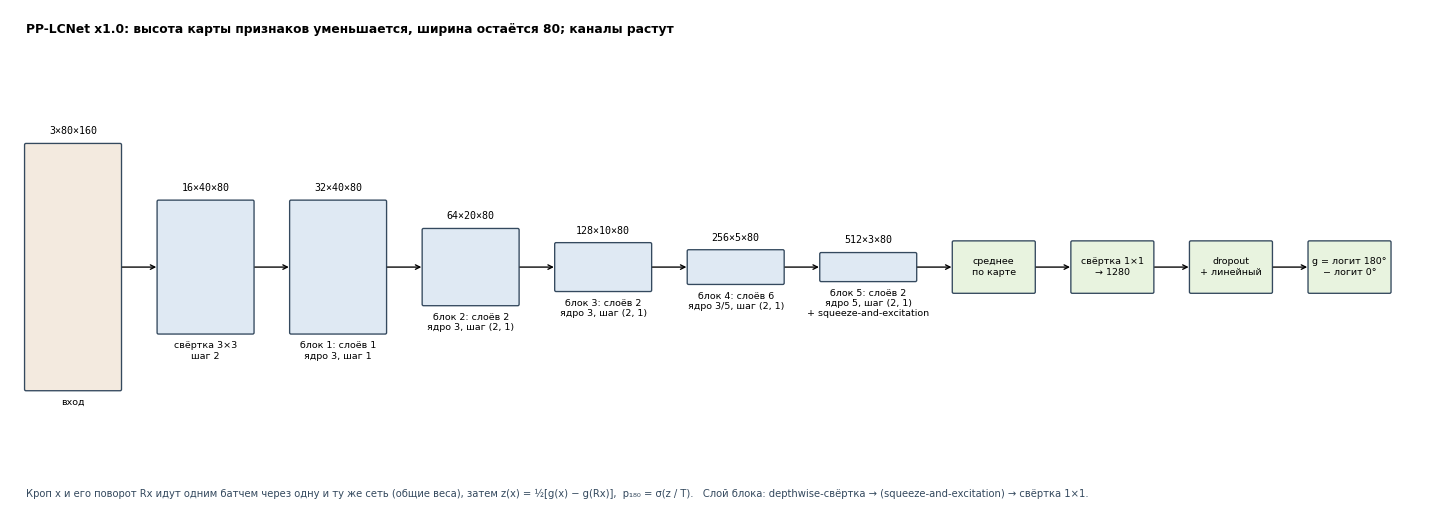

In [5]:
# Конфигурация PP-LCNet: (размер ядро, вход, выход, шаг, использование squeeze-and-excitation) для каждого слоя.
# Шаг (2, 1) сжимает только высоту. Для входа 80×160 к концу сети остаётся 3×80. CNN свернет всю высоту в каналы
BLOCKS = [
    [(3, 16, 32, 1, False)],
    [(3, 32, 64, (2, 1), False), (3, 64, 64, 1, False)],
    [(3, 64, 128, (2, 1), False), (3, 128, 128, 1, False)],
    [(3, 128, 256, (2, 1), False)] + [(5, 256, 256, 1, False)] * 5,
    [(5, 256, 512, (2, 1), True), (5, 512, 512, 1, True)],
]


def make_div(v, d=8):
    # Число каналов после умножения на scale, округлённое до кратного 8
    n = max(d, int(v + d / 2) // d * d)
    return n + d if n < 0.9 * v else n


class ConvBNAct(nn.Module):
    # Свёртка + BatchNorm + HardSwish ((x · ReLU6(x + 3) / 6 быстрое приближение Swish из MobileNetV3)
    # Подробнее про HardSwish: arXiv 1905.02244
    def __init__(self, ci, co, k, s, groups=1):
        super().__init__()
        self.convolution = nn.Conv2d(ci, co, k, s, (k - 1) // 2, groups=groups, bias=False)
        self.normalization = nn.BatchNorm2d(co)
        self.activation = nn.Hardswish()

    def forward(self, x):
        return self.activation(self.normalization(self.convolution(x)))


class SE(nn.Module):
    # Squeeze-and-Excitation: перевзвешивает каналы по их среднему по картинке
    def __init__(self, c):
        super().__init__()
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.convolutions = nn.ModuleList([
            nn.Conv2d(c, c // 4, 1), nn.ReLU(), nn.Conv2d(c // 4, c, 1), nn.Hardsigmoid(),
        ])

    def forward(self, x):
        s = self.avg_pool(x)
        for layer in self.convolutions:
            s = layer(s)
        return x * s


class DSConv(nn.Module):
    # Depthwise-свёртка (каждый канал отдельно) -> SE -> pointwise-свёртка 1x1
    def __init__(self, ci, co, k, s, se):
        super().__init__()
        self.depthwise_convolution = ConvBNAct(ci, ci, k, s, groups=ci)
        self.squeeze_excitation_module = SE(ci) if se else nn.Identity()
        self.pointwise_convolution = ConvBNAct(ci, co, 1, 1)

    def forward(self, x):
        x = self.squeeze_excitation_module(self.depthwise_convolution(x))
        return self.pointwise_convolution(x)


class Block(nn.Module):
    def __init__(self, layers):
        super().__init__()
        self.layers = nn.ModuleList(layers)

    def forward(self, x):
        for layer in self.layers:
            x = layer(x)
        return x


class Encoder(nn.Module):
    def __init__(self, scale):
        super().__init__()
        c = lambda v: make_div(v * scale)
        self.convolution = ConvBNAct(3, c(16), 3, 2)
        self.blocks = nn.ModuleList([
            Block([DSConv(c(ci), c(co), k, s, se) for k, ci, co, s, se in block])
            for block in BLOCKS
        ])

    def forward(self, x):
        x = self.convolution(x)
        for block in self.blocks:
            x = block(x)
        return x


class PPLCNet(nn.Module):
    # Имена модулей совпадают с model.safetensors PaddleOCR для того, чтобы подгружать веса
    def __init__(self, scale):
        super().__init__()
        self.encoder = Encoder(scale)
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.last_convolution = nn.Conv2d(make_div(512 * scale), 1280, 1, bias=False)
        self.act_fn = nn.Hardswish()
        self.dropout = nn.Dropout(0.2)
        self.head = nn.Linear(1280, 2)  # логиты классов 0° и 180°

    def forward(self, x):
        x = self.act_fn(self.last_convolution(self.avg_pool(self.encoder(x))))
        return self.head(self.dropout(x.flatten(1)))


class Orient(nn.Module):
    """Логит p_180, антисимметричный по построению: z(Rx) = -z(x)."""

    def __init__(self, backbone):
        super().__init__()
        self.backbone = backbone

    def forward(self, x):
        # Картинка и её поворот одним батчем, g = логит (180° минус 0°)
        out = self.backbone(torch.cat([x, torch.flip(x, [2, 3])]))
        g = (out[:, 1] - out[:, 0]).reshape(2, -1)  # reshape, а не len(x): иначе ONNX зашьёт батч
        return 0.5 * (g[0] - g[1])  # z(x) = ½[g(x) - g(Rx)]


def load_pretrained():
    model = PPLCNet(CFG.scale)
    state = load_file(hf_hub_download(CFG.pplcnet_repo, 'model.safetensors'))
    state['head.weight'] = state['head.weight'] * 0.8 # Paddle-dropout на инференсе умножает на 1 - p = 0.8, PyTorch не делает так
    model.load_state_dict(state)
    return Orient(model)

## Данные

* **RusTitW** (`train/real`, `test/real`): рамки абзацев, битые рамки
  и рамки меньше 8 px отбрасываем. Train/val делим по фото, чтобы избежать ликов. Все рамки один раз
  кэшируем на локальный диск.
* **TextOCR** (`train`: 5 шардов, `test`): реальные кропы слов. Размер читаем
  из заголовка PNG, без декодирования.

`clean` означает `w >= h` и хотя бы одну букву. По нему считаем основные метрики.

In [6]:
def rustitw_boxes(split):
    # Разбираем info.csv RusTitW: одна строка это одно фото со списком рамок в долях от размера
    info = pd.read_csv(CFG.rustitw / split / 'real' / 'info.csv')
    rows = []
    for name, w, h, boxes in info[['image_name', 'width', 'height', 'box_and_label']].values:
        for i, box in enumerate(json.loads(boxes)[0]):
            # Битые рамки: координаты записаны в пикселях, а не в долях, выходят за 1
            if box['left'] + box['width'] > 1.02 or box['top'] + box['height'] > 1.02:
                continue
            x0, y0 = round(box['left'] * w), round(box['top'] * h)
            x1 = min(w, round((box['left'] + box['width']) * w))
            y1 = min(h, round((box['top'] + box['height']) * h))
            if x1 - x0 < 8 or y1 - y0 < 8:  # слишком мелкие рамки
                continue
            text = box.get('label', '').replace('\\/n', '\n')  # перенос строки записан как \/n
            rows.append((name, i, (x0, y0, x1, y1), text))
    return pd.DataFrame(rows, columns=['photo', 'box_id', 'box', 'text'])


def crop_photo(split, photo, group):
    # Вырезаем все рамки одного фото за одно открытие; уже вырезанные не трогаем
    source = CFG.rustitw / split / 'real' / 'images' / photo
    paths = [CFG.crops / split / f'{Path(photo).stem}_{i}.png' for i in group.box_id]
    if not all(p.exists() for p in paths):
        with Image.open(source) as image:
            image = image.convert('RGB')
            for box, path in zip(group.box, paths):
                image.crop(box).save(path)
    return paths


def rustitw_frame(split):
    # Вырезаем кропы на локальный /tmp
    df = rustitw_boxes(split)
    (CFG.crops / split).mkdir(parents=True, exist_ok=True)
    groups = list(df.groupby('photo', sort=False))
    with ThreadPoolExecutor(CFG.crop_threads) as executor:
        jobs = executor.map(lambda item: crop_photo(split, *item), groups)
        paths = list(tqdm(jobs, total=len(groups), desc=f'RusTitW {split}: crops'))
    df = pd.concat([g for _, g in groups]).assign(ref=[str(p) for ps in paths for p in ps])
    w, h = zip(*[(box[2] - box[0], box[3] - box[1]) for box in df.box])
    return df.assign(src='rustitw', w=w, h=h)[['src', 'photo', 'text', 'w', 'h', 'ref']]


def textocr_frame(dataset, split):
    # Размеры кропов читаем из заголовка PNG, не декодируя картинку целиком
    raw = dataset.cast_column('image', HFImage(decode=False))
    sizes = []
    for row in tqdm(raw, desc=f'TextOCR {split}: sizes'):
        with Image.open(io.BytesIO(row['image']['bytes'])) as image:
            sizes.append(image.size)
    w, h = zip(*sizes)
    return pd.DataFrame({'src': 'textocr', 'photo': '', 'text': dataset['text'], 'w': w, 'h': h,
                         'ref': [f'{split}:{i}' for i in range(len(dataset))]})


def add_flags(df):
    # Алфавит, число строк и признак clean: w >= h (не вертикальный кроп) и есть хотя бы одна буква
    text = df.text.astype(str)
    cyrillic = text.str.contains('[А-Яа-яЁё]')
    latin = text.str.contains('[A-Za-z]')
    script = np.select([cyrillic & latin, cyrillic, latin],
                       ['mixed', 'cyrillic', 'latin'], 'no_letters')
    return df.assign(script=script, n_lines=text.str.count('\n') + 1,
                     clean=(df.w >= df.h) & (script != 'no_letters'))


# RusTitW: train/val
# test/real: отложенная выборка
rustitw = rustitw_frame('train')
photos = rustitw.photo.unique()
val_photos = set(np.random.default_rng(CFG.seed).permutation(photos)
                 [:int(len(photos) * CFG.rustitw_val_frac)])
rustitw_train = rustitw[~rustitw.photo.isin(val_photos)]
rustitw_val = rustitw[rustitw.photo.isin(val_photos)]
rustitw_test = rustitw_frame('test')

# TextOCR: из train-шардов берём val (textocr_val_size кропов) и train, test — отложенная выборка
shards = [f'data/train-{i:05d}-of-00005.parquet' for i in range(CFG.textocr_train_shards)]
HF = {
    'train': load_dataset(CFG.textocr_repo, data_files={'train': shards},
                          split='train', verification_mode='no_checks'),
    'test': load_dataset(CFG.textocr_repo, data_files={'test': 'data/test-00000-of-00001.parquet'},
                         split='test', verification_mode='no_checks'),
}
textocr = textocr_frame(HF['train'], 'train').sample(frac=1, random_state=CFG.seed)
textocr_val = textocr.iloc[:CFG.textocr_val_size]
textocr_train = textocr.iloc[CFG.textocr_val_size:]
textocr_test = textocr_frame(HF['test'], 'test')

SPLITS = {
    'train': add_flags(pd.concat([rustitw_train, textocr_train], ignore_index=True)),
    'val': add_flags(pd.concat([rustitw_val, textocr_val], ignore_index=True)),
    'test': add_flags(pd.concat([rustitw_test, textocr_test], ignore_index=True)),
}
# Сколько кропов в каждой части и какая доля из них clean
summary = pd.concat({k: v.groupby('src').agg(n=('clean', 'size'), clean=('clean', 'mean'))
                     for k, v in SPLITS.items()})
summary.round(3)

RusTitW train: crops:   0%|          | 0/24262 [00:00<?, ?it/s]

RusTitW test: crops:   0%|          | 0/3782 [00:00<?, ?it/s]

README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00005.parquet:   0%|          | 0.00/399M [00:00<?, ?B/s]

data/train-00001-of-00005.parquet:   0%|          | 0.00/403M [00:00<?, ?B/s]

data/train-00002-of-00005.parquet:   0%|          | 0.00/392M [00:00<?, ?B/s]

... (4 outputs left out)

Generating test split:   0%|          | 0/14669 [00:00<?, ? examples/s]

TextOCR train: sizes:   0%|          | 0/91373 [00:00<?, ?it/s]

TextOCR test: sizes:   0%|          | 0/14669 [00:00<?, ?it/s]

n  clean
      src                  
train rustitw  54625  0.831
      textocr  88373  0.847
val   rustitw   5926  0.828
      textocr   3000  0.843
test  rustitw  10693  0.808
      textocr  14669  0.847

## Аугментации и загрузчик

Сначала уменьшаем кроп до +-2× целевого размера, потом аугментируем:
джиттер рамки, наклон, уменьшение до 8–32 px (в тесте много мелких кропов),
блюр, окклюдер, засветка, яркость/контраст, шум, инверсия, grayscale, JPEG.
Поворот на 180° делаем в батче на GPU: модель антисимметрична, метка просто меняет знак.

In [10]:
# Нормализация ImageNet: на ней предобучены веса PaddleOCR
# Стандартные значения
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)


def load_image(ref):
    # ref — либо 'train:<индекс>' / 'test:<индекс>' (строка TextOCR в HF), либо путь к кропу RusTitW
    if ref.startswith(('train:', 'test:')):
        split, index = ref.split(':')
        return HF[split][int(index)]['image'].convert('RGB')
    with Image.open(ref) as image:
        return image.convert('RGB')


def to_tensor(image):
    # Растягиваем в 80×160 (высота × ширина) без сохранения пропорций, как при обучении PaddleOCR
    pixels = np.asarray(image.resize((CFG.img_w, CFG.img_h), Image.BILINEAR), np.float32) / 255
    return (torch.from_numpy(pixels).permute(2, 0, 1) - MEAN) / STD


def shrink(image):
    # Сразу уменьшаем большие кропы до +-2× размера входа: иначе аугментации на полноразмерных
    # кропах (до тысяч пикселей) становятся главным тормозом обучения
    w, h = image.size
    scale = min(1.0, 2 * CFG.img_h / h, 4 * CFG.img_w / w)
    if scale < 1:
        return image.resize((max(8, round(w * scale)), max(8, round(h * scale))))
    return image


def mean_color(image):
    return tuple(np.asarray(image).reshape(-1, 3).mean(0).astype(int))


def augment(image):
    image = shrink(image)
    h = image.height

    # Неточная рамка: случайно обрезаем или добавляем поля до 12% высоты с каждой стороны
    if random.random() < 0.7:
        pad = [int(random.uniform(-0.12, 0.12) * h) for _ in range(4)]
        image = ImageOps.expand(image, tuple(max(0, -v) for v in pad), fill=mean_color(image))
        cut = [max(0, v) for v in pad]
        image = image.crop((cut[0], cut[1], max(cut[0] + 4, image.width - cut[2]),
                            max(cut[1] + 4, image.height - cut[3])))
    # Небольшой наклон
    if random.random() < 0.3:
        image = image.rotate(random.uniform(-4, 4), Image.BILINEAR, fillcolor=mean_color(image))
    
    # Мелкий текст
    if random.random() < 0.5:
        target_height = random.randint(8, 32)
        if image.height > target_height:
            new_width = max(4, round(image.width * target_height / image.height))
            image = image.resize((new_width, target_height), Image.BILINEAR)
    
    # Размытие
    if random.random() < 0.25:
        image = image.filter(ImageFilter.GaussianBlur(random.uniform(0.3, 1.5)))

    pixels = np.asarray(image, np.float32)
    height, width = pixels.shape[:2]
    
    # Посторонний объект: закрашенный эллипс у верхнего или нижнего края
    if random.random() < 0.2:
        grid_y, grid_x = np.mgrid[:height, :width]
        center_y = random.choice([0, height]) + random.uniform(-0.2, 0.2) * height
        center_x = random.uniform(0, width)
        radius_y = random.uniform(0.2, 0.9) * height
        radius_x = random.uniform(0.1, 0.3) * width
        inside = ((grid_y - center_y) / radius_y) ** 2 + ((grid_x - center_x) / radius_x) ** 2 < 1
        pixels[inside] = np.random.randint(0, 256, 3)
    
    # Неравномерная засветка: линейный градиент яркости
    if random.random() < 0.2:
        gradient_x = np.linspace(-1, 1, width)[None, :] * random.uniform(-70, 70)
        gradient_y = np.linspace(-1, 1, height)[:, None] * random.uniform(-50, 50)
        pixels = pixels + (gradient_x + gradient_y)[..., None]
    
    # Контраст и яркость
    if random.random() < 0.5:
        mean = pixels.mean()
        pixels = (pixels - mean) * random.uniform(0.6, 1.4) + mean + random.uniform(-30, 30)
    
    # Шум
    if random.random() < 0.3:
        pixels = pixels + np.random.normal(0, random.uniform(2, 12), pixels.shape)
    image = Image.fromarray(np.clip(pixels, 0, 255).astype(np.uint8))

    # Инверсия цвета
    if random.random() < 0.2:
        image = ImageOps.invert(image)
    if random.random() < 0.15:
        image = ImageOps.grayscale(image).convert('RGB')
    
    # Артефакты JPEG
    if random.random() < 0.4:
        buffer = io.BytesIO()
        image.save(buffer, 'JPEG', quality=random.randint(20, 90))
        image = Image.open(buffer).convert('RGB')
    return image


class CropDataset(Dataset):
    # Отдаёт кропы в нормальной ориентации
    # поворот на 180° и метку делает цикл обучения на GPU
    def __init__(self, refs, train):
        self.refs, self.train = list(refs), train

    def __len__(self):
        return len(self.refs)

    def __getitem__(self, i):
        image = load_image(self.refs[i])
        return to_tensor(augment(image) if self.train else image)


def train_loader():
    # Каждый источник (RusTitW, TextOCR) даёт в среднем равную долю батча, независимо от размера
    df = SPLITS['train']
    df = df[(df.w >= df.h) & (df.text.str.strip() != '')]
    weights = 1.0 / df.src.map(df.src.value_counts()).to_numpy()
    sampler = WeightedRandomSampler(torch.tensor(weights), CFG.epoch_size,
                                    generator=torch.Generator().manual_seed(CFG.seed))
    return DataLoader(CropDataset(df.ref, train=True), CFG.batch_size, sampler=sampler,
                      num_workers=CFG.num_workers, pin_memory=True, drop_last=True)

## Оценка

Модель антисимметрична, поэтому достаточно одного прогона по upright-кропам:
для перевёрнутого кропа логит $-z$, метка 1. Температура $T$ подбирается по Brier на val

In [11]:
sigmoid = lambda z: 1 / (1 + np.exp(-z))


@torch.no_grad()
def predict(model, df):
    # Логиты z для кропов в нормальной ориентации (без аугментаций)
    model.eval()
    loader = DataLoader(CropDataset(df.ref, train=False), 512, num_workers=CFG.num_workers)
    logits = []
    for x in tqdm(loader, desc='predict', leave=False):
        with torch.autocast('cuda'):
            logits.append(model(x.to(DEVICE)).float().cpu().numpy())
    return np.concatenate(logits)


def pairs(z):
    # Модель антисимметрична: для повёрнутого кропа логит равен -z, а метка 1.
    # Поэтому по одному прогону получаем обе ориентации каждого кропа
    return np.r_[z, -z], np.r_[np.zeros(len(z)), np.ones(len(z))]


def ece(y, p, bins=15):
    # Expected Calibration Error: насколько уверенность модели расходится с реальной точностью,
    # среднее по корзинам уверенности от 0.5 до 1
    confidence, correct = np.maximum(p, 1 - p), (p > 0.5) == y
    edges = np.linspace(0.5, 1, bins + 1)
    bin_index = np.clip(np.digitize(confidence, edges) - 1, 0, bins - 1)
    return sum(np.mean(bin_index == b) * abs(correct[bin_index == b].mean()
                                             - confidence[bin_index == b].mean())
               for b in range(bins) if np.any(bin_index == b))


def metrics(z, T):
    z, y = pairs(z)
    p = sigmoid(z / T)
    return {'1-Brier': 1 - np.mean((p - y) ** 2), 'AUC': roc_auc_score(y, z), 'ECE': ece(y, p)}


def fit_temperature(z):
    # Температура T: одно число, при котором Brier на val минимален; p = sigmoid(z / T)
    z, y = pairs(z)
    return minimize_scalar(lambda temperature: np.mean((sigmoid(z / temperature) - y) ** 2),
                           bounds=(0.05, 20), method='bounded').x


def slices(df):
    # Срезы для отчёта; clean = не вертикальный кроп (w >= h) и есть хотя бы одна буква
    is_rustitw, is_textocr, is_clean = df.src == 'rustitw', df.src == 'textocr', df.clean
    is_cyrillic, is_latin = df.script == 'cyrillic', df.script == 'latin'
    return {
        'RusTitW clean': is_rustitw & is_clean,
        'RusTitW all': is_rustitw,
        'RusTitW cyr': is_rustitw & is_clean & is_cyrillic,
        'RusTitW cyr 1-line': is_rustitw & is_clean & is_cyrillic & (df.n_lines == 1),
        'RusTitW cyr multi-line': is_rustitw & is_clean & is_cyrillic & (df.n_lines > 1),
        'RusTitW lat': is_rustitw & is_clean & is_latin,
        'RusTitW vertical': is_rustitw & (df.w < df.h),
        'TextOCR clean': is_textocr & is_clean,
        'TextOCR all': is_textocr,
    }


def report(z, df, T):
    # Таблица 1-Brier / AUC / ECE по всем срезам
    return pd.DataFrame({name: metrics(z[mask.to_numpy()], T)
                         for name, mask in slices(df).items()}).T


def val_score(z):
    # Критерий выбора эпохи: среднее 1-Brier на val по RusTitW clean и TextOCR clean при T = 1
    df = SPLITS['val']
    return np.mean([metrics(z[mask.to_numpy()], 1.0)['1-Brier']
                    for mask in (slices(df)['RusTitW clean'], slices(df)['TextOCR clean'])])

## Обучение

BCE на антисимметричном логите, AdamW, one-cycle LR, Automatic fixed precision.
После каждой эпохи смотрим val (среднее 1-Brier по RusTitW clean и TextOCR clean)
и сохраняем лучшую эпоху.

In [12]:
model = load_pretrained().to(DEVICE)
loader = train_loader()
optimizer = torch.optim.AdamW(model.parameters(), lr=CFG.lr, weight_decay=CFG.weight_decay)

# One-cycle: разогрев первые warmup_frac шагов, затем плавное снижение скорости обучения к нулю
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=CFG.lr,
                                                pct_start=CFG.warmup_frac,
                                                total_steps=CFG.epochs * len(loader))

# Смешанная точность: масштабируем лосс, чтобы малые градиенты не обнулились во float16
scaler = torch.amp.GradScaler()


def snapshot(model):
    # Копия весов, чтобы сохранить лучшую эпоху
    return {name: tensor.clone() for name, tensor in model.state_dict().items()}


# Эпоха 0 как стартовая точка
z_val = predict(model, SPLITS['val'])
history = [{'epoch': 0, 'loss': np.nan, 'val': val_score(z_val)}]
print(f"init (PaddleOCR + антисимметрия): val {history[0]['val']:.4f}")
best_val, best_state = history[0]['val'], snapshot(model)

for epoch in range(1, CFG.epochs + 1):
    model.train()
    epoch_start, losses = time.time(), []
    for x in tqdm(loader, desc=f'epoch {epoch}/{CFG.epochs}', leave=False):
        x = x.to(DEVICE, non_blocking=True)
        # Метка бесплатно: случайную половину батча поворачиваем на 180° и ставим y = 1
        y = (torch.rand(len(x), device=DEVICE) < 0.5).float()
        x = torch.where(y[:, None, None, None] > 0, torch.flip(x, [2, 3]), x)
        with torch.autocast('cuda'):
            loss = F.binary_cross_entropy_with_logits(model(x).float(), y)
        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        losses.append(loss.item())

    score = val_score(predict(model, SPLITS['val']))
    history.append({'epoch': epoch, 'loss': np.mean(losses), 'val': score})
    print(f'epoch {epoch}: loss {np.mean(losses):.4f}  val {score:.4f}  '
          f'({time.time() - epoch_start:.0f}s)')
    if score > best_val:
        best_val, best_state = score, snapshot(model)

# Возвращаем веса лучшей по val эпохи
model.load_state_dict(best_state)
torch.save(best_state, CFG.work / 'model.pt')
pd.DataFrame(history)

predict:   0%|          | 0/18 [00:00<?, ?it/s]

init (PaddleOCR + антисимметрия): val 0.9161


epoch 1/8:   0%|          | 0/234 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ac8f5f45da0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
    if w.is_alive():
       ^^^^^^^^^^^^
  File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ac8f5f45da0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 16

predict:   0%|          | 0/18 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ac8f5f45da0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
    if w.is_alive():
       ^^^^^^^^^^^^
  File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ac8f5f45da0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 16

... (22 outputs left out)

epoch 8/8:   0%|          | 0/234 [00:00<?, ?it/s]

predict:   0%|          | 0/18 [00:00<?, ?it/s]

epoch 8: loss 0.1564  val 0.9617  (136s)


,epoch,loss,val
0,0,NaN,0.916131
1,1,0.331763,0.940110
2,2,0.219859,0.949463
3,3,0.200921,0.949827
4,4,0.189978,0.952777
5,5,0.174964,0.958689
6,6,0.162840,0.960291
7,7,0.157685,0.961910
8,8,0.156425,0.961719


## Калибровка на val и отчёт на held-out test

In [15]:
# Подбираем T по val
val_clean = SPLITS['val'].clean.to_numpy()
T = fit_temperature(predict(model, SPLITS['val'])[val_clean])

# Отчёт на отложенной выборке, которая не участвовала
# ни в обучении, ни в выборе эпохи, ни в подборе T
z_test = predict(model, SPLITS['test'])
test_report = report(z_test, SPLITS['test'], T)
print(f'T = {T:.3f}')
test_report.round(4)

predict:   0%|          | 0/18 [00:00<?, ?it/s]

predict:   0%|          | 0/50 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ac8f5f45da0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
    if w.is_alive():
       ^^^^^^^^^^^^
  File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ac8f5f45da0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 16

T = 1.171


,1-Brier,AUC,ECE
RusTitW clean,0.9764,0.9961,0.0062
RusTitW all,0.9582,0.9890,0.0072
RusTitW cyr,0.9782,0.9966,0.0064
RusTitW cyr 1-line,0.9739,0.9949,0.0104
RusTitW cyr multi-line,0.9830,0.9981,0.0077
RusTitW lat,0.9667,0.9925,0.0124
RusTitW vertical,0.8503,0.8657,0.0469
TextOCR clean,0.9563,0.9834,0.0065
TextOCR all,0.9360,0.9716,0.0098


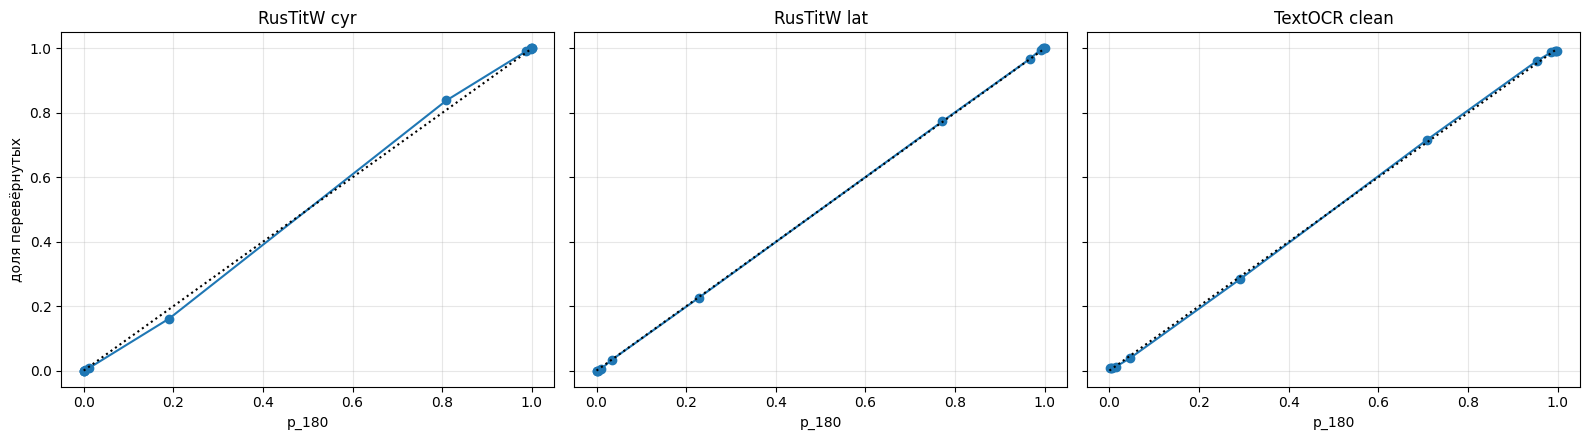

In [16]:
# калибровка на отложенной выборке: кропы разбиты на 12 бинов
# у идеально откалиброванной модели точки лежат на диагонали
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, name in zip(axes, ['RusTitW cyr', 'RusTitW lat', 'TextOCR clean']):
    z, y = pairs(z_test[slices(SPLITS['test'])[name].to_numpy()])
    p = sigmoid(z / T)
    bins = pd.qcut(p, 12, labels=False, duplicates='drop')  # корзины с равным числом кропов
    ax.plot(pd.Series(p).groupby(bins).mean(), pd.Series(y).groupby(bins).mean(), 'o-')
    ax.plot([0, 1], [0, 1], 'k:')  # идеальная калибровка
    ax.set(title=name, xlabel='p_180')
    ax.grid(alpha=0.3)
axes[0].set_ylabel('доля перевёрнутых')
plt.tight_layout()
plt.show()

## Экспорт в ONNX и скорость на CPU

В ONNX входит и антисимметричная голова: на входе кроп 3×80×160, на выходе логит $z$,
$p_{180} = \sigma(z / T)$.

In [17]:
# Экспорт в ONNX вместе с антисимметричной головой: на входе кроп 3×80×160,
# на выходе логит z; итоговая вероятность p_180 = sigmoid(z / T)
model_cpu = model.cpu().eval()
onnx_path = CFG.work / 'model.onnx'
torch.onnx.export(model_cpu, torch.randn(1, 3, CFG.img_h, CFG.img_w), onnx_path,
                  input_names=['x'], output_names=['logit_180'], opset_version=17,
                  dynamic_axes={'x': {0: 'n'}, 'logit_180': {0: 'n'}}, dynamo=False)

# Проверка на батче из 8: ONNX совпадает с PyTorch и антисимметричен, z(Rx) = -z(x)
x = torch.randn(8, 3, CFG.img_h, CFG.img_w)
session = ort.InferenceSession(str(onnx_path), providers=['CPUExecutionProvider'])
z_onnx = session.run(None, {'x': x.numpy()})[0]
z_onnx_rotated = session.run(None, {'x': torch.flip(x, [2, 3]).numpy()})[0]
with torch.no_grad():
    z_torch = model_cpu(x).numpy()
print(f'|ONNX - PyTorch| = {np.abs(z_onnx - z_torch).max():.1e}, '
      f'|z(x) + z(Rx)| = {np.abs(z_onnx + z_onnx_rotated).max():.1e}')

# Всё, что нужно для инференса без этого блокнота: температура и препроцессинг
meta = {'T': T, 'img_h': CFG.img_h, 'img_w': CFG.img_w,
        'mean': MEAN.flatten().tolist(), 'std': STD.flatten().tolist()}
(CFG.work / 'calibration.json').write_text(json.dumps(meta, indent=1))

# Скорость на CPU: 1 поток, один кроп за раз (оба прохода головы внутри)
options = ort.SessionOptions()
options.intra_op_num_threads = 1
session = ort.InferenceSession(str(onnx_path), options, providers=['CPUExecutionProvider'])
single = np.random.randn(1, 3, CFG.img_h, CFG.img_w).astype(np.float32)
for _ in range(20):
    session.run(None, {'x': single})
start = time.perf_counter()
for _ in range(200):
    session.run(None, {'x': single})
latency_ms = (time.perf_counter() - start) / 200 * 1e3

n_params = sum(p.numel() for p in model_cpu.parameters())
print(f'параметров {n_params:,}, ONNX {onnx_path.stat().st_size / 1e6:.2f} MB, '
      f'CPU 1 поток: {latency_ms:.2f} ms/кроп')
model = model_cpu.to(DEVICE)

/tmp/ipykernel_58/2584961571.py:5: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(model_cpu, torch.randn(1, 3, CFG.img_h, CFG.img_w), onnx_path,


|ONNX - PyTorch| = 1.2e-06, |z(x) + z(Rx)| = 0.0e+00
параметров 1,674,082, ONNX 6.70 MB, CPU 1 поток: 18.05 ms/кроп


In [18]:
# FP16: веса и вычисления в половинной точности, вход и выход остаются float32.
fp16_path = CFG.work / 'model_fp16.onnx'
onnx.save(float16.convert_float_to_float16(onnx.load(str(onnx_path)), keep_io_types=True),
          str(fp16_path))


def onnx_logits(path, df):
    # Логиты ONNX-модели для кропов из таблицы
    session = ort.InferenceSession(str(path), providers=['CPUExecutionProvider'])
    loader = DataLoader(CropDataset(df.ref, train=False), 256, num_workers=CFG.num_workers)
    return np.concatenate([session.run(None, {'x': x.numpy()})[0]
                           for x in tqdm(loader, desc=path.stem, leave=False)])


def cpu_latency(path, repeats=100):
    # Время на один кроп: CPU, 1 поток, batch 1
    options = ort.SessionOptions()
    options.intra_op_num_threads = 1
    session = ort.InferenceSession(str(path), options, providers=['CPUExecutionProvider'])
    x = np.random.randn(1, 3, CFG.img_h, CFG.img_w).astype(np.float32)
    for _ in range(10):  # прогрев
        session.run(None, {'x': x})
    start = time.perf_counter()
    for _ in range(repeats):
        session.run(None, {'x': x})
    return (time.perf_counter() - start) / repeats * 1e3


# Сверка FP16 с FP32 на 2000 случайных кропах отложенной выборки
check = SPLITS['test'].sample(2000, random_state=CFG.seed)
z_fp32, z_fp16 = onnx_logits(onnx_path, check), onnx_logits(fp16_path, check)
latency_fp16_ms = cpu_latency(fp16_path)
print(f'FP32: {onnx_path.stat().st_size / 1e6:.2f} MB, {latency_ms:.2f} ms/кроп')
print(f'FP16: {fp16_path.stat().st_size / 1e6:.2f} MB, {latency_fp16_ms:.2f} ms/кроп')
print(f'знак совпал: {np.mean((z_fp32 > 0) == (z_fp16 > 0)):.4f}, '
      f'max |p32 - p16|: {np.abs(sigmoid(z_fp32 / T) - sigmoid(z_fp16 / T)).max():.4f}')

# Т общая для обеих версий
meta.update(model_fp32='model.onnx', model_fp16='model_fp16.onnx')
(CFG.work / 'calibration.json').write_text(json.dumps(meta, indent=1))

/usr/local/lib/python3.12/dist-packages/onnxconverter_common/float16.py:70: UserWarning: the float32 number -7.541574120750738e-08 will be truncated to -1e-07
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/onnxconverter_common/float16.py:52: UserWarning: the float32 number 2.2894873930728865e-12 will be truncated to 1e-07
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/onnxconverter_common/float16.py:70: UserWarning: the float32 number -1.9154664833431756e-12 will be truncated to -1e-07
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/onnxconverter_common/float16.py:52: UserWarning: the float32 number 1.0306746567323444e-08 will be truncated to 1e-07
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/onnxconverter_common/float16.py:70: UserWarning: the float32 number -1.030726348716371e-08 will be truncated to -1e-07
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/onnxconverter_common/float16.py:52: UserWarning: the float32 number 1.67950245234

model:   0%|          | 0/8 [00:00<?, ?it/s]

model_fp16:   0%|          | 0/8 [00:00<?, ?it/s]

FP32: 6.70 MB, 18.05 ms/кроп
FP16: 3.37 MB, 13.51 ms/кроп
знак совпал: 0.9995, max |p32 - p16|: 0.0112


281

## Сабмит для нашего теста

Тест только прогоняется через модель: $T$ взята с val, на тесте ничего не подбирается.

predict:   0%|          | 0/40 [00:00<?, ?it/s]

20000 кропов, средний p_180 = 0.478


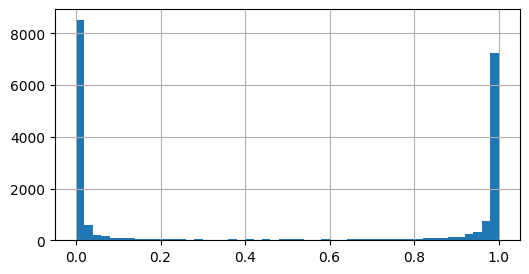

In [19]:
files = sorted(CFG.avito_test.glob('*.png'))
assert files, f'Нет PNG в {CFG.avito_test}: укажите путь к тесту в Config.avito_test'
z_avito = predict(model, pd.DataFrame({'ref': [str(f) for f in files]}))
submission = pd.DataFrame({'image_id': [f.stem for f in files],
                           'p_180': sigmoid(z_avito / T)})
submission.to_csv(CFG.work / 'submission.csv', index=False)

# Проверка без разметки: у откалиброванной модели средняя p_180 это оценка доли перевёрнутых кропов
print(f'{len(submission)} кропов, средний p_180 = {submission.p_180.mean():.3f}')
submission.p_180.hist(bins=50, figsize=(6, 3))
plt.show()

In [20]:
# Сводка прогона для README и проверки: конфиг, температура, история обучения,
# метрики на отложенной выборке, скорость и статистика сабмита
(CFG.work / 'report.json').write_text(json.dumps({
    'config': {name: str(value) for name, value in vars(CFG).items()},
    'T': T,
    'history': history,
    'test': test_report.round(5).to_dict(orient='index'),
    'latency_ms_cpu_1thread': {'fp32': latency_ms, 'fp16': latency_fp16_ms},
    'submission': {'crops': len(submission), 'mean_p_180': float(submission.p_180.mean())},
}, indent=1, ensure_ascii=False))

2485